In [ ]:
import os, json, random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
SEED=42
random.seed(SEED); np.random.seed(SEED)
os.makedirs('outputs',exist_ok=True)
import torch, torchvision
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
print('Torch:',torch.__version__,'GPU:',torch.cuda.is_available())
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)

Torch: 2.14.1+cu130 GPU: True


In [ ]:
# ImageNet pretrained: dùng ảnh 224x224 và normalization ImageNet.
train_tf=transforms.Compose([transforms.Resize((224,224)),transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
eval_tf=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
full_train_aug=datasets.CIFAR100('./data',train=True,download=True,transform=train_tf)
full_train_eval=datasets.CIFAR100('./data',train=True,download=False,transform=eval_tf)
test_ds=datasets.CIFAR100('./data',train=False,download=True,transform=eval_tf)
indices=torch.randperm(50000,generator=torch.Generator().manual_seed(SEED)).tolist()
train_ds=torch.utils.data.Subset(full_train_aug,indices[5000:])
val_ds=torch.utils.data.Subset(full_train_eval,indices[:5000])
loader_args={'batch_size':64,'num_workers':2,'pin_memory':torch.cuda.is_available()}
train_loader=DataLoader(train_ds,shuffle=True,**loader_args)
val_loader=DataLoader(val_ds,shuffle=False,**loader_args)
test_loader=DataLoader(test_ds,shuffle=False,**loader_args)
class_names=test_ds.classes
print('Train:',len(train_ds),'Val:',len(val_ds),'Test:',len(test_ds))

100%|██████████| 169M/169M [19:24<00:00, 145kB/s]


Train: 45000 Val: 5000 Test: 10000


In [ ]:
# Fine-tune toàn bộ mạng; nếu Colab GPU hạn chế, giảm EPOCHS hoặc BATCH SIZE.
weights=models.ResNet18_Weights.DEFAULT
model=models.resnet18(weights=weights)
model.fc=nn.Linear(model.fc.in_features,100)
model=model.to(device)
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)
EPOCHS=8
history={'train_loss':[],'train_accuracy':[],'val_loss':[],'val_accuracy':[]}
best_val=-1
for epoch in range(EPOCHS):
 model.train(); running_loss=correct=total=0
 for images,labels in train_loader:
  images,labels=images.to(device),labels.to(device)
  optimizer.zero_grad(set_to_none=True)
  logits=model(images);loss=criterion(logits,labels)
  loss.backward();optimizer.step()
  running_loss+=loss.item()*labels.size(0)
  correct+=(logits.argmax(1)==labels).sum().item();total+=labels.size(0)
 history['train_loss'].append(running_loss/total);history['train_accuracy'].append(correct/total)
 model.eval();running_loss=correct=total=0
 with torch.no_grad():
  for images,labels in val_loader:
   images,labels=images.to(device),labels.to(device)
   logits=model(images);loss=criterion(logits,labels)
   running_loss+=loss.item()*labels.size(0)
   correct+=(logits.argmax(1)==labels).sum().item();total+=labels.size(0)
 history['val_loss'].append(running_loss/total);history['val_accuracy'].append(correct/total)
 if history['val_accuracy'][-1]>best_val:
  best_val=history['val_accuracy'][-1]
  torch.save(model.state_dict(),'outputs/best_resnet18_cifar100.pth')
 print(f"Epoch {epoch+1}/{EPOCHS}: train_acc={history['train_accuracy'][-1]:.4f}, val_acc={history['val_accuracy'][-1]:.4f}, val_loss={history['val_loss'][-1]:.4f}")
with open('outputs/history_cifar100.json','w') as f:json.dump(history,f,indent=2)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]


Epoch 1/8: train_acc=0.5823, val_acc=0.7298, val_loss=0.9859
Epoch 2/8: train_acc=0.7852, val_acc=0.7672, val_loss=0.7967
Epoch 3/8: train_acc=0.8595, val_acc=0.7770, val_loss=0.7360
Epoch 4/8: train_acc=0.9096, val_acc=0.7866, val_loss=0.7150
Epoch 5/8: train_acc=0.9400, val_acc=0.7882, val_loss=0.7496
Epoch 6/8: train_acc=0.9592, val_acc=0.7920, val_loss=0.7397
Epoch 7/8: train_acc=0.9708, val_acc=0.7932, val_loss=0.7318
Epoch 8/8: train_acc=0.9776, val_acc=0.7856, val_loss=0.7974


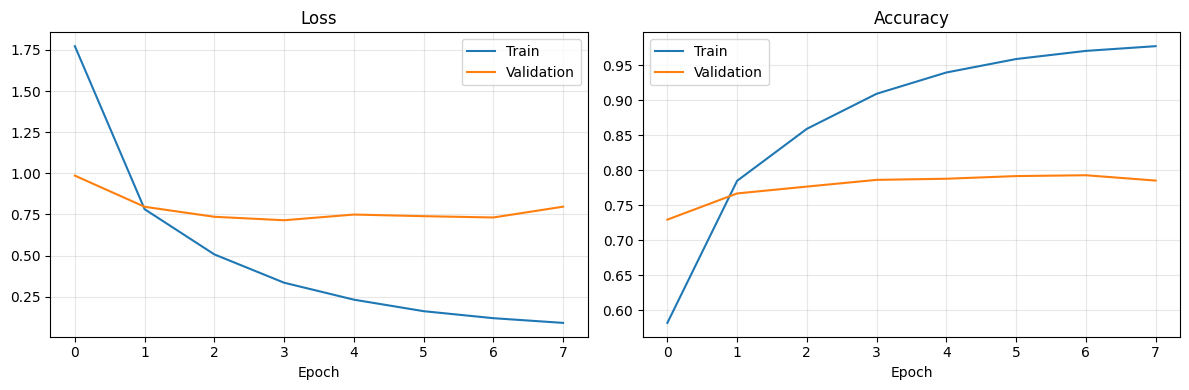

Test loss: 0.765 Test accuracy: 0.7919


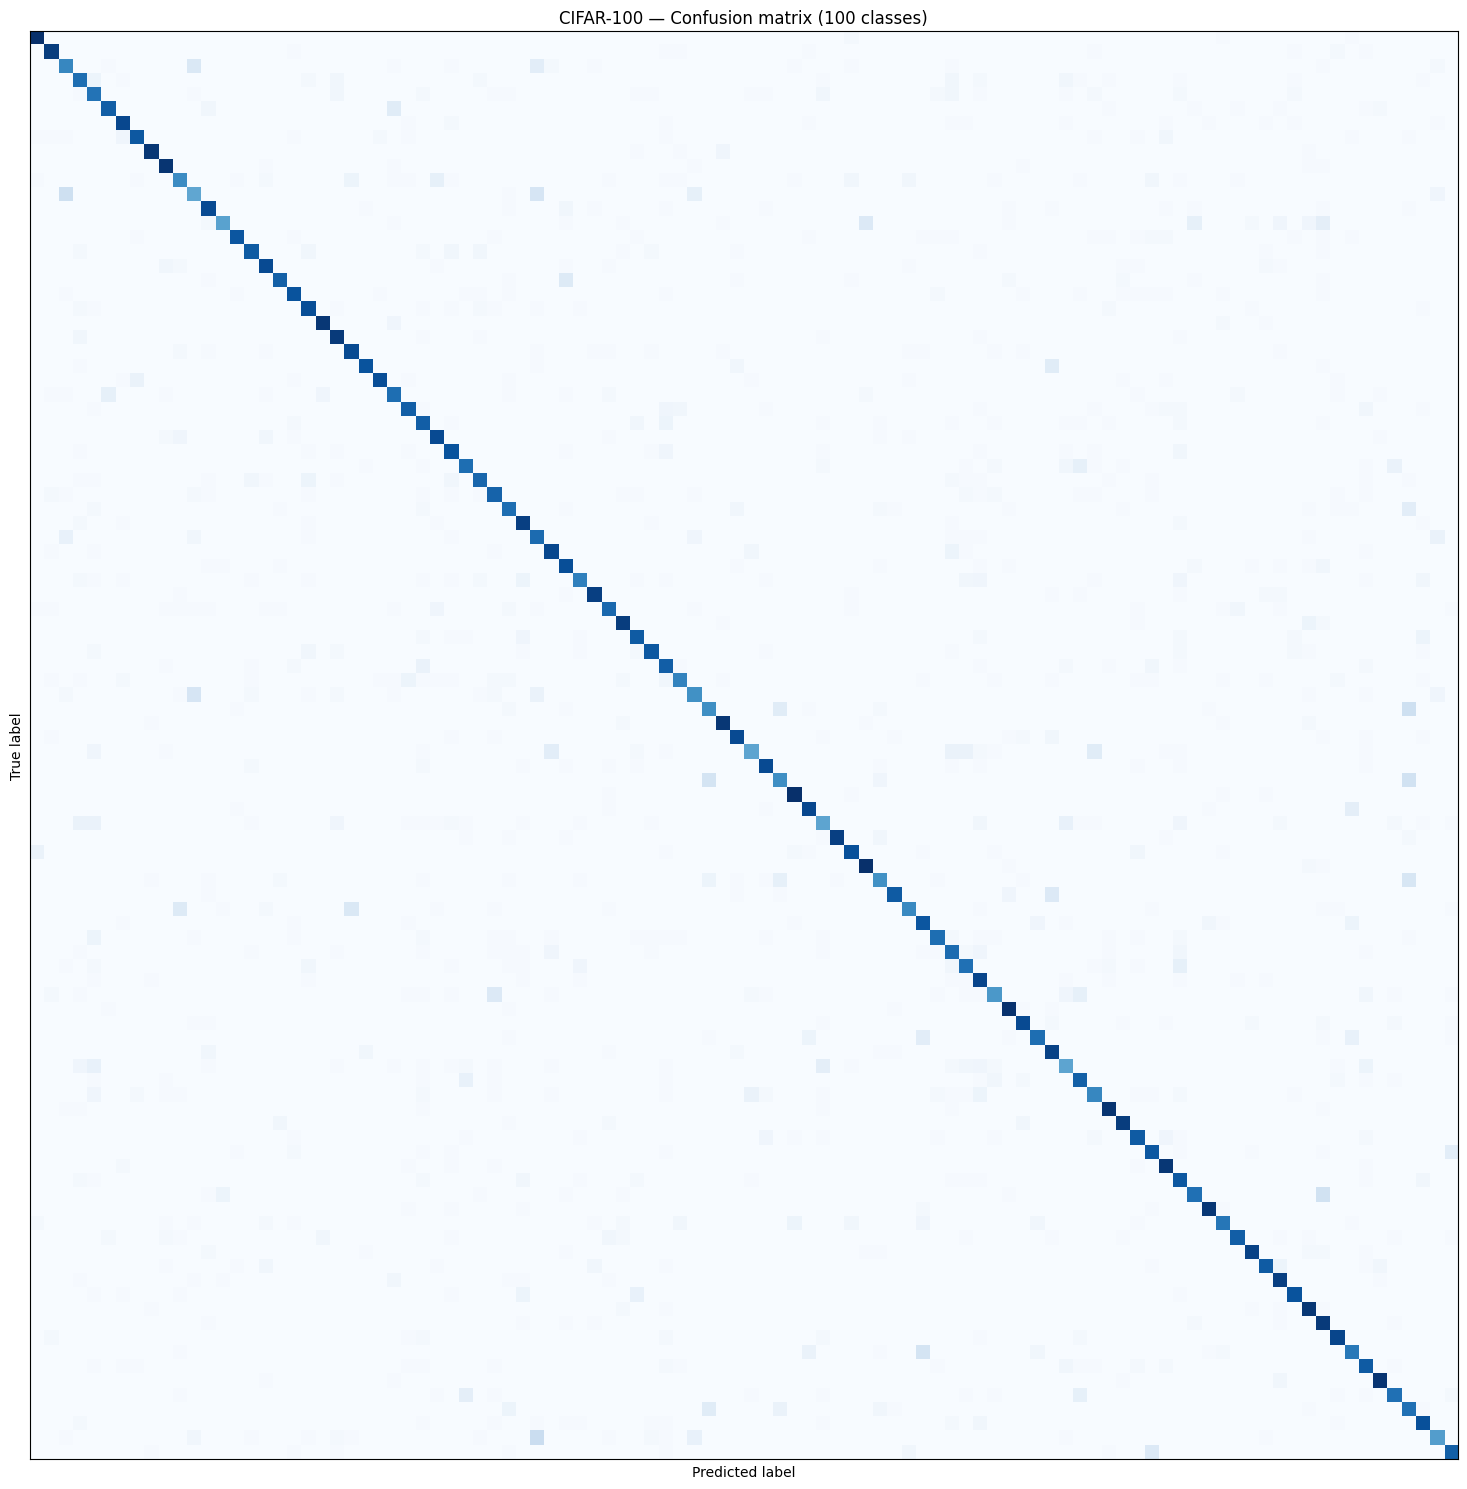

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['loss','accuracy']):
 ax.plot(history['train_'+metric],label='Train');ax.plot(history['val_'+metric],label='Validation')
 ax.set_title(metric.capitalize());ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.3)
plt.tight_layout();plt.savefig('outputs/cifar100_training.png',dpi=160);plt.show()
model.load_state_dict(torch.load('outputs/best_resnet18_cifar100.pth',map_location=device,weights_only=True))
model.eval();test_loss=correct=total=0;actual=[];predicted=[]
with torch.no_grad():
 for images,labels in test_loader:
  images,labels=images.to(device),labels.to(device)
  logits=model(images);loss=criterion(logits,labels)
  test_loss+=loss.item()*labels.size(0)
  preds=logits.argmax(1)
  correct+=(preds==labels).sum().item();total+=labels.size(0)
  actual.extend(labels.cpu().tolist());predicted.extend(preds.cpu().tolist())
accuracy=correct/total;test_loss/=total
print('Test loss:',round(test_loss,4),'Test accuracy:',round(accuracy,4))
report=classification_report(actual,predicted,target_names=class_names,output_dict=True,zero_division=0)
with open('outputs/classification_report_cifar100.json','w') as f:json.dump(report,f,indent=2)
# 100x100 confusion matrix rất lớn: lưu ảnh và hiển thị rút gọn để dễ xem.
fig,ax=plt.subplots(figsize=(16,15))
ConfusionMatrixDisplay.from_predictions(actual,predicted,ax=ax,include_values=False,xticks_rotation='vertical',cmap='Blues',colorbar=False)
ax.set_xticks([]);ax.set_yticks([]);ax.set_title('CIFAR-100 — Confusion matrix (100 classes)')
plt.tight_layout();plt.savefig('outputs/cifar100_confusion_matrix.png',dpi=180);plt.show()
with open('outputs/results_cifar100.json','w') as f:json.dump({'test_loss':test_loss,'test_accuracy':accuracy,'best_val_accuracy':best_val,'epochs_run':len(history['train_loss']),'seed':SEED,'pretrained':'torchvision ResNet18_Weights.DEFAULT'},f,indent=2)

In [ ]:
import shutil
shutil.make_archive('cifar100_outputs','zip','outputs')
from google.colab import files
files.download('cifar100_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>